<a href="https://colab.research.google.com/github/nimben/Deep-Learning/blob/main/SAC/SAC_Pendulum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install stable-baselineS3 gymnasium matplotlib

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Using cuda device
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Training SAC Agent..
----------------------------------
| rollout/           |           |
|    ep_len_mean     | 200       |
|    ep_rew_mean     | -1.37e+03 |
| time/              |           |
|    episodes        | 4         |
|    fps             | 2976      |
|    time_elapsed    | 0         |
|    total_timesteps | 800       |
----------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


----------------------------------
| rollout/           |           |
|    ep_len_mean     | 200       |
|    ep_rew_mean     | -1.29e+03 |
| time/              |           |
|    episodes        | 8         |
|    fps             | 211       |
|    time_elapsed    | 7         |
|    total_timesteps | 1600      |
| train/             |           |
|    actor_loss      | 17.1      |
|    critic_loss     | 0.288     |
|    ent_coef        | 0.837     |
|    ent_coef_loss   | -0.289    |
|    learning_rate   | 0.0003    |
|    n_updates       | 599       |
----------------------------------
----------------------------------
| rollout/           |           |
|    ep_len_mean     | 200       |
|    ep_rew_mean     | -1.39e+03 |
| time/              |           |
|    episodes        | 12        |
|    fps             | 138       |
|    time_elapsed    | 17        |
|    total_timesteps | 2400      |
| train/             |           |
|    actor_loss      | 42.9      |
|    critic_loss    

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


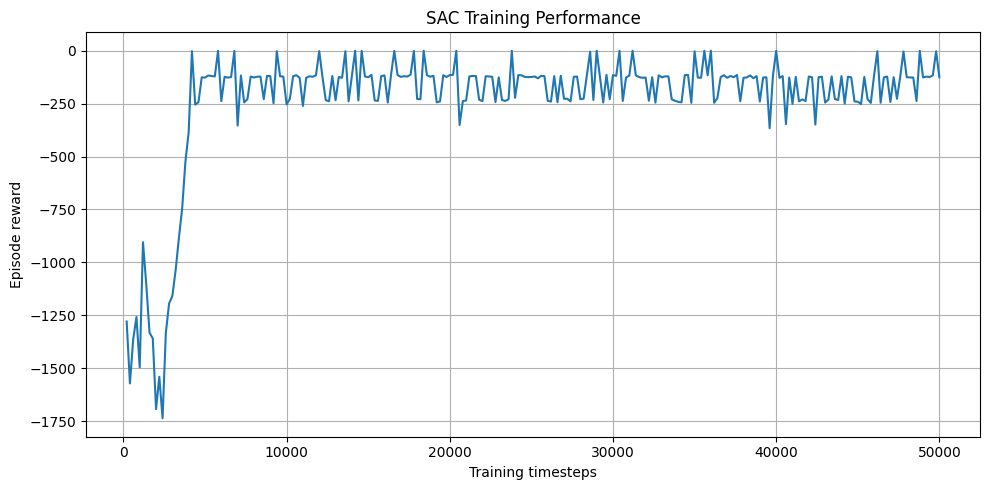

Episode 1: Reward = -117.05
Episode 2: Reward = -243.55
Episode 3: Reward = -119.49
Episode 4: Reward = -123.45
Episode 5: Reward = -116.63
Average evaluation reward: -144.04


In [ ]:
import os
import gymnasium as gym
import matplotlib.pyplot as plt

from stable_baselines3 import SAC
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.results_plotter import load_results, ts2xy

ENV_NAME = "Pendulum-v1"
LOG_DIR = "sac_logs"

os.makedirs(LOG_DIR, exist_ok=True)

env = Monitor(gym.make(ENV_NAME),
filename = os.path.join(LOG_DIR, "training"))

model = SAC(
    policy = "MlpPolicy",
    env = env,
    learning_rate = 3e-4,
    buffer_size = 100000,
    learning_starts = 1000,
    batch_size = 256,
    tau = 0.005,
    gamma = 0.99,
    verbose = 1,
    seed = 42
)

print("Training SAC Agent..")
model.learn(total_timesteps=50000)
model.save("sac_pendulum")

print("Training complete!")
print("model saved sac_pendulum.zip")

env.close()


results = load_results(LOG_DIR)
timesteps, rewards = ts2xy(results, "timesteps")

plt.figure(figsize=(10,5))
plt.plot(timesteps, rewards)
plt.xlabel("Training timesteps")
plt.ylabel("Episode reward")
plt.title("SAC Training Performance")
plt.grid(True)
plt.tight_layout()
plt.savefig("sac_training_rewards.png")
plt.show()


eval_env = gym.make(ENV_NAME)
episode_rewards = []

for episode in range(5):
   obs, info = eval_env.reset(seed=100 + episode)
   total_reward = 0.0
   terminated = False
   truncated = False


   while not (terminated or truncated):
        action, _ = model.predict(
            obs,
            deterministic=True
        )

        obs, reward, terminated, truncated, info = (
            eval_env.step(action)
        )

        total_reward += float(reward)

   episode_rewards.append(total_reward)

   print(
        f"Episode {episode + 1}: "
        f"Reward = {total_reward:.2f}"
    )

eval_env.close()

print(
    "Average evaluation reward:",
    round(sum(episode_rewards) / len(episode_rewards), 2)
)






In [ ]:
!pip install -q "gymnasium[classic-control]"

In [ ]:

import gymnasium as gym
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from stable_baselines3 import SAC

# Load the saved model if it is not already in memory
if "model" not in globals():
    model = SAC.load("sac_pendulum")

# Create an environment that supports visual rendering
eval_env = gym.make(
    "Pendulum-v1",
    render_mode="rgb_array"
)

# Reset the environment
obs, info = eval_env.reset(seed=42)

# Store simulation frames
frames = []

terminated = False
truncated = False

# Run the trained agent
while not (terminated or truncated):

    # Get action from trained SAC agent
    action, _ = model.predict(
        obs,
        deterministic=True
    )

    # Perform action
    obs, reward, terminated, truncated, info = (
        eval_env.step(action)
    )

    # Capture the current simulation image
    frames.append(eval_env.render())

eval_env.close()

# Create animation
fig, ax = plt.subplots(figsize=(5, 5))
ax.axis("off")

img = ax.imshow(frames[0])

def update(frame):
    img.set_data(frames[frame])
    return [img]

animation = FuncAnimation(
    fig,
    update,
    frames=len(frames),
    interval=50,
    blit=True
)

# Display animation in Google Colab
display(HTML(animation.to_jshtml()))

plt.close(fig)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
